# D10. Поиск формата весов

Проверил, помогает ли менять форму сетки при близком бюджете памяти. Начал с условной таблицы уровней, затем запустил на двух моделях четыре семейства форматов и контроли.

**Результат.** Отражаемая сетка улучшила PPL на SmolLM2 относительно AWQ, но trellis-контроль оказался лучше. На OPT лучший результат остался у нативного GPTQ.

[Назад: референсы](../D09/experiments.ipynb) · [Протокол дня](README.md) · [Дальше: поиск кодов](../D11/experiments.ipynb)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

day = Path("quantization/research/D10")
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / day / "results").is_dir():
        results = directory / day / "results"
        break
else:
    raise FileNotFoundError(f"Не найдены CSV в {day}/results")

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})

## Условная таблица уровней

Таблица поиска задаёт значения, которые декодируются из 4-битных кодов. В пилоте гистограмма определяет выбор формы сетки. Свободный контроль тоже использует две таблицы при том же логическом бюджете, но может выбирать форму свободнее. Сравниваю три конфигурации на одинаковых калибровочных подмножествах SmolLM2.

In [2]:
pilot = pd.read_csv(results / "lut_pilot.csv")
methods = ["AWQ_native", "flat_LUT", "histogram", "free2_LUT"]
lut = pilot[pilot["method"].isin(methods)].pivot(index="method", columns="subset", values="ppl")
lut = lut.loc[methods]
assert lut.notna().all().all()
lut["Среднее PPL"] = lut.mean(axis=1)
display(lut.round(4))

subset,0.0,1.0,2.0,Среднее PPL
method,,,,
AWQ_native,18.0577,17.9987,18.1013,18.0526
flat_LUT,18.0576,17.8901,18.0549,18.0009
histogram,17.9778,17.8603,17.9110,17.9164
free2_LUT,17.7953,17.7658,17.8570,17.8060


У гистограммного варианта PPL **17,9164**, у AWQ **18,0526**. Свободный контроль даёт **17,8060**, поэтому вклад условия по гистограмме отдельно не подтвердился.

## Расширенный прогон

Проверил палитры с селектором внутри слова scale, отражение окна общей сетки, перенос поправок между соседними кодами и таблицы с сохранением моментов. Всего 17 конфигураций на 3 подмножествах и 2 моделях, плюс 7 строк нативных референсов. Калибровочные подмножества частично пересекаются. Для экспериментальных вариантов OPT исходные scale и zero point получены из RTN, GPTQ оценивался отдельно.

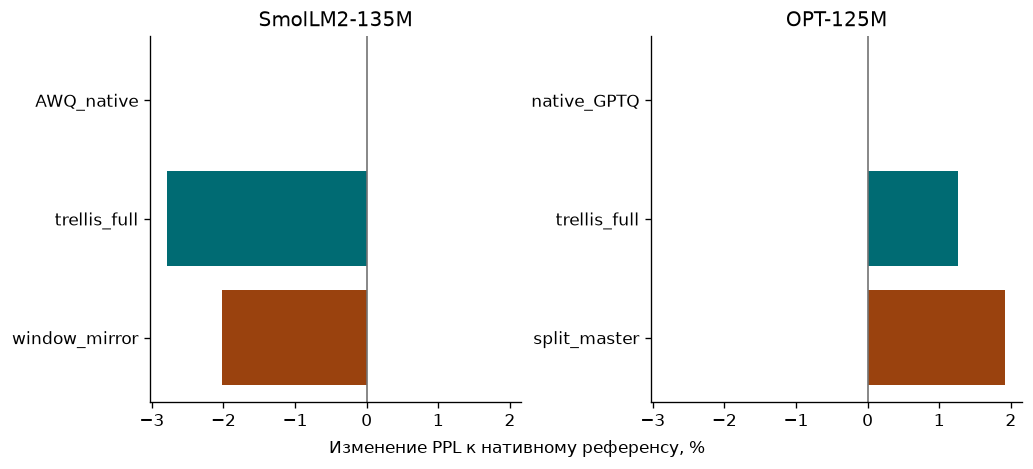

n       ppl  weight_mse
model        method                                
SmolLM2-135M AWQ_native     3  18.05257    0.000460
             trellis_full   3  17.54885    0.000486
             window_mirror  3  17.68862    0.000412
OPT-125M     native_GPTQ    3  28.31842    0.000030
             trellis_full   3  28.67642    0.000175
             split_master   3  28.86198    0.000016

In [3]:
runs = pd.read_csv(results / "format_search.csv")
assert len(runs) == 109
assert not runs.duplicated(["model", "method", "subset"]).any()
summary = runs.groupby(["model", "method"]).agg(
    n=("ppl", "size"), ppl=("ppl", "mean"), weight_mse=("weight_mse", "mean"))

comparisons = {
    "SmolLM2-135M": ("AWQ_native", "trellis_full", "window_mirror"),
    "OPT-125M": ("native_GPTQ", "trellis_full", "split_master"),
}
colors = ["#69788b", "#006b73", "#9a420e"]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8), sharex=True, layout="constrained")
selected = []
for ax, (model, methods) in zip(axes, comparisons.items()):
    rows = summary.loc[model].loc[list(methods)]
    selected.append(rows)
    ppl = rows["ppl"]
    delta = 100 * (ppl / ppl.iloc[0] - 1)
    ax.barh(ppl.index, delta, color=colors)
    ax.axvline(0, color=".45", linewidth=1)
    ax.set_title(model)
    ax.invert_yaxis()
fig.supxlabel("Изменение PPL к нативному референсу, %", fontsize=10)
plt.show()
display(pd.concat(selected, keys=comparisons, names=["model"]).round({"ppl": 5, "weight_mse": 8}))

На SmolLM2 `window_mirror` даёт **17,6886** против **17,5488** у `trellis_full`. На OPT `split_master` даёт **28,8620** против **28,3184** у GPTQ. Ни один из девяти кандидатных вариантов не выполнил критерии качества на обеих моделях.

В сохранённом аудите 14 382 матричных декодирования совпали между CPU и GPU, восемь восстановлений полной модели дали ту же NLL. Качество измерял после восстановления в FP32. `logical_bytes` описывает логическое представление весов и метаданных. Измерений INT4-задержки в этом прогоне нет.

## Таблицы и исходные записи

Слева — CSV, которые читает ноутбук. Справа — имена исходных локальных записей.

- [format_search.csv](results/format_search.csv) · `private/queued_search_round2_v2/downloaded_metadata/results/ppl_weight_metrics.csv`
- [lut_pilot.csv](results/lut_pilot.csv) · `private/candidate1_ppl/analysis/ppl_weight_metrics.csv`